### Test evaluation and model comparison


In [ ]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
)


In [ ]:

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data/raw/data.csv"
assert RAW_PATH.is_file(), f"Missing raw data: {RAW_PATH}"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [ ]:

from src.data import get_or_create_split
from src.evaluation import evaluate_predictions
from src.schema import ROW_ID, TARGET


In [2]:
# None uses the selection saved by notebook 05.
# To switch, set "random_forest", "logistic_regression", "xgboost", or "prior_baseline".
# This changes the selected reports; all saved models are still evaluated.
MODEL_TO_USE = None

model_path = PROJECT_ROOT / "models/loan_models.joblib"
if not model_path.is_file():
    raise FileNotFoundError("Run notebooks/05_model.ipynb before evaluating the test set.")
bundle = joblib.load(model_path)
pipelines = bundle["pipelines"]
selected_model = bundle["selected_model"] if MODEL_TO_USE is None else MODEL_TO_USE
if selected_model not in pipelines:
    raise ValueError(f"MODEL_TO_USE must be None or one of {tuple(pipelines)}.")
threshold = float(bundle["threshold"])

df = pd.read_csv(RAW_PATH)
split = get_or_create_split(df, path=PROJECT_ROOT / "data/processed/split.parquet")
test = split["test"]
y_test = test[TARGET]
X_test = test.drop(columns=TARGET)


In [3]:
probabilities_by_model = {}
predictions_by_model = {}
test_records = []

for name, pipeline in pipelines.items():
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    probabilities_by_model[name] = probabilities
    predictions_by_model[name] = (probabilities >= threshold).astype(int)
    metrics = evaluate_predictions(y_test, probabilities, threshold=threshold)
    test_records.append({"model": name, **metrics, "selected_for_use": name == selected_model})

test_comparison = pd.DataFrame(test_records).set_index("model")
display(test_comparison)
display(pd.Series({
    "training_selected_model": bundle["selected_model"],
    "selected_model_for_reports": selected_model,
    "threshold": threshold,
    "test_rows": len(test),
    "class_1_fraction": float(y_test.mean()),
}, name="evaluation_context").to_frame())


,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,selected_for_use
model,,,,,,,,
prior_baseline,0.500000,0.224133,0.775867,0.500000,0.000000,0.000000,0.000000,False
random_forest,0.712788,0.406969,0.655337,0.654039,0.353959,0.651686,0.458751,False
logistic_regression,0.706393,0.394279,0.657169,0.649317,0.352872,0.635085,0.453671,False
xgboost,0.717427,0.414026,0.780407,0.537179,0.558743,0.096336,0.164337,True


,evaluation_context
training_selected_model,xgboost
selected_model_for_reports,xgboost
threshold,0.5
test_rows,103742
class_1_fraction,0.224133


ROC AUC and average precision measure probability ranking.
Precision, recall, F1, accuracy, and balanced accuracy use the saved threshold.
The class 1 fraction is the reference average precision for an uninformative ranking.
Labels remain `class 0` and `class 1` until the original target encoding is confirmed.


precision    recall  f1-score        support
model               metric                                                    
prior_baseline      class 0        0.775867  1.000000  0.873790   80490.000000
                    class 1        0.000000  0.000000  0.000000   23252.000000
                    accuracy       0.775867  0.775867  0.775867       0.775867
                    macro avg      0.387934  0.500000  0.436895  103742.000000
                    weighted avg   0.601970  0.775867  0.677945  103742.000000
random_forest       class 0        0.867081  0.656392  0.747168   80490.000000
                    class 1        0.353959  0.651686  0.458751   23252.000000
                    accuracy       0.655337  0.655337  0.655337       0.655337
                    macro avg      0.610520  0.654039  0.602959  103742.000000
                    weighted avg   0.752074  0.655337  0.682524  103742.000000
logistic_regression class 0        0.862911  0.663548  0.750211   80490.000000
                    class 1        0.352872  0.635085  0.453671   23252.000000
                    accuracy       0.657169  0.657169  0.657169       0.657169
                    macro avg      0.607892  0.649317  0.601941  103742.000000
                    weighted avg   0.748594  0.657169  0.683746  103742.000000
xgboost             class 0        0.789317  0.978022  0.873595   80490.000000
                    class 1        0.558743  0.096336  0.164337   23252.000000
                    accuracy       0.780407  0.780407  0.780407       0.780407
                    macro avg      0.674030  0.537179  0.518966  103742.000000
                    weighted avg   0.737638  0.780407  0.714627  103742.000000

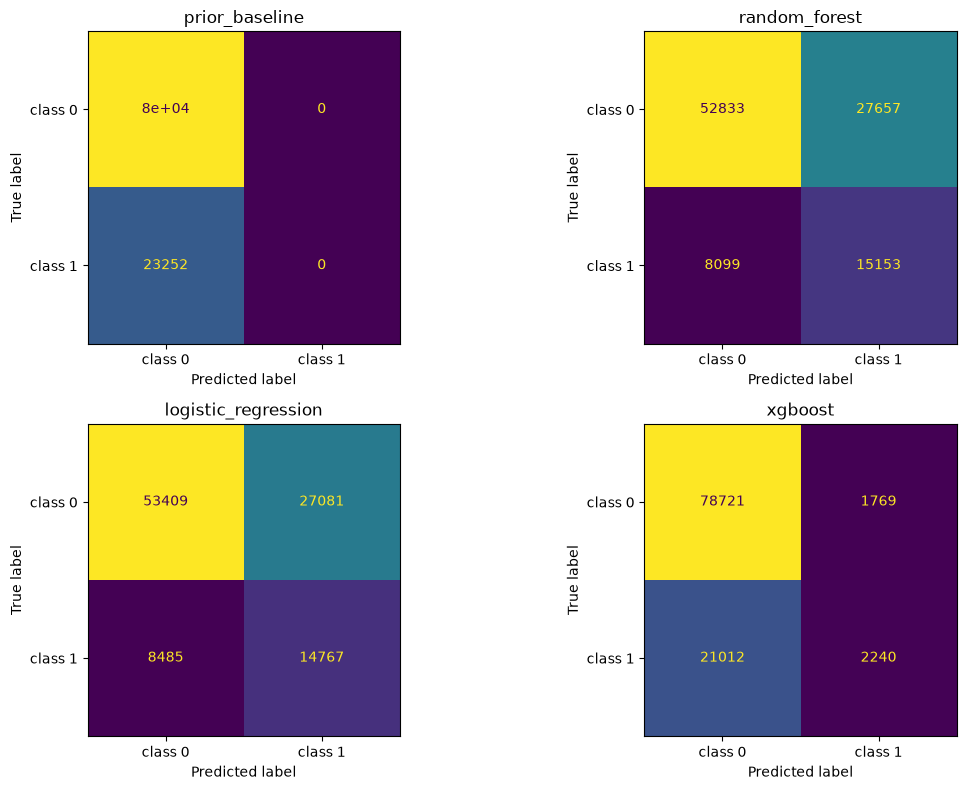

In [4]:
classification_reports = {}
confusion_matrices = {}

for name, predictions in predictions_by_model.items():
    classification_reports[name] = classification_report(
        y_test, predictions, labels=[0, 1], target_names=["class 0", "class 1"],
        output_dict=True, zero_division=0,
    )
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1])

display(pd.concat(
    {name: pd.DataFrame(report).T for name, report in classification_reports.items()},
    names=["model", "metric"],
))

rows = (len(pipelines) + 1) // 2
fig, axes = plt.subplots(rows, 2, figsize=(12, 4 * rows), squeeze=False)
for ax, (name, matrix) in zip(axes.flat, confusion_matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=["class 0", "class 1"]).plot(
        ax=ax, colorbar=False,
    )
    ax.set_title(name)
for ax in axes.flat[len(pipelines):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()


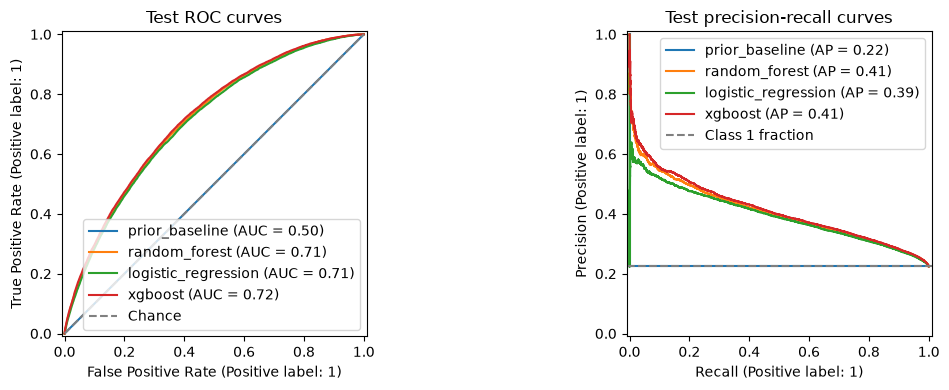

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, probabilities in probabilities_by_model.items():
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].axhline(float(y_test.mean()), linestyle="--", color="gray", label="Class 1 fraction")
axes[0].set_title("Test ROC curves")
axes[1].set_title("Test precision-recall curves")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()


Save all-model comparisons, metrics, classification reports, and row-level predictions.
The existing `test_metrics.json`, `test_predictions.csv`, and `test_confusion_matrix.csv`
contain results for `selected_model` only.
`_row_id` preserves split membership and is excluded from model features.


In [6]:
reports_path = PROJECT_ROOT / "reports"
reports_path.mkdir(parents=True, exist_ok=True)
test_comparison.to_csv(reports_path / "test_model_comparison.csv")

model_metrics = {}
for record in test_records:
    model_metrics[record["model"]] = {
        "threshold": threshold,
        "test_rows": len(test),
        "class_1_fraction": float(y_test.mean()),
        **{name: value for name, value in record.items() if name != "model"},
    }
all_metrics = {
    "selected_model": selected_model,
    "training_selected_model": bundle["selected_model"],
    "selection_metric": bundle["selection_metric"],
    "models": model_metrics,
}
(reports_path / "test_metrics_all_models.json").write_text(
    json.dumps(all_metrics, indent=2, allow_nan=False) + "\n", encoding="utf-8",
)
(reports_path / "test_classification_reports.json").write_text(
    json.dumps(classification_reports, indent=2, allow_nan=False) + "\n", encoding="utf-8",
)
selected_metrics = {"selected_model": selected_model, **model_metrics[selected_model]}
(reports_path / "test_metrics.json").write_text(
    json.dumps(selected_metrics, indent=2, allow_nan=False) + "\n", encoding="utf-8",
)

all_predictions = test.loc[:, [ROW_ID, TARGET]].copy()
for name in pipelines:
    all_predictions[f"{name}_probability"] = probabilities_by_model[name]
    all_predictions[f"{name}_prediction"] = predictions_by_model[name]
all_predictions.to_csv(reports_path / "test_predictions_all_models.csv", index=False)

test_predictions = test.loc[:, [ROW_ID, TARGET]].copy()
test_predictions["probability"] = probabilities_by_model[selected_model]
test_predictions["prediction"] = predictions_by_model[selected_model]
test_predictions.to_csv(reports_path / "test_predictions.csv", index=False)
confusion = pd.DataFrame(
    confusion_matrices[selected_model],
    index=pd.Index(["class 0", "class 1"], name="actual"),
    columns=pd.Index(["class 0", "class 1"], name="predicted"),
)
confusion.to_csv(reports_path / "test_confusion_matrix.csv")
print(f"Reports use: {selected_model}")
print(reports_path)


Reports use: xgboost
C:\Users\USER\Desktop\Portfolio\supervised\ml-anomaly-detection\reports
